# House Prices Prediction Pipeline

This notebook provides an end-to-end pipeline for the Kaggle House Prices dataset, including detailed preprocessing, feature engineering, explicit ordinal mappings, handling skewness, one-hot encoding, and a modeling section with cross-validation, hyperparameter tuning, and feature importance visualization. Comments explain the rationale for each step. Ensure `train.csv` and `test.csv` are placed in the same directory as this notebook when running.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import skew, probplot
from scipy.special import boxcox1p
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_val_score, RandomizedSearchCV
from sklearn.linear_model import Lasso, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 200)


Train shape: (1460, 80)
Test shape: (1459, 79)


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   int64  
 1   MSZoning       1460 non-null   object 
 2   LotFrontage    1201 non-null   float64
 3   LotArea        1460 non-null   int64  
 4   Street         1460 non-null   object 
 5   Alley          91 non-null     object 
 6   LotShape       1460 non-null   object 
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   object 
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   object 
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuil

None

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1379.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,567.240411,1057.429452,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,6.517808,0.613014,1978.506164,1.767123,472.980137,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,441.866955,438.705324,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,1.625393,0.644666,24.689725,0.747315,213.804841,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1900.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,223.000000,795.750000,882.000000,0.000000,0.000000,1129.500000,0.000000,0.000000,1.000000,0.000000,2.000000,1.000000,5.000000,0.000000,1961.000000,1.000000,334.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,477.500000,991.500000,1087.000000,0.000000,0.000000,1464.000000,0.000000,0.000000,2.000000,0.000000,3.000000,1.000000,6.000000,1.000000,1980.000000,2.000000,480.000000,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,808.000000,1298.250000,1391.250000,728.000000,0.000000,1776.750000,1.000000,0.000000,2.000000,1.000000,3.000000,1.000000,7.000000,1.000000,2002.000000,2.000000,576.000000,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,2336.000000,6110.000000,4692.000000,2065.000000,572.000000,5642.000000,3.000000,2.000000,3.000000,2.000000,8.000000,3.000000,14.000000,3.000000,2010.000000,4.000000,1418.000000,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


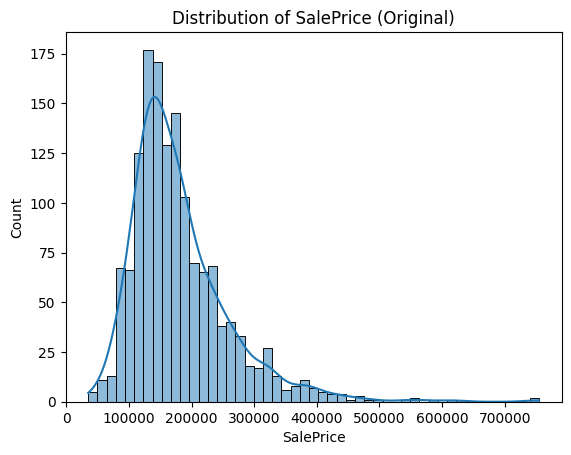

Skewness of SalePrice: 1.88


In [2]:
# Load data
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
test_ID = test['Id'] if 'Id' in test.columns else None

# Drop ID columns
if 'Id' in train.columns:
    train.drop('Id', axis=1, inplace=True)
if 'Id' in test.columns:
    test.drop('Id', axis=1, inplace=True)

print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")

# Quick look
display(train.head())
display(train.info())

# Describe numeric features
display(train.describe())

# Check target distribution
import seaborn as sns
sns.histplot(train['SalePrice'], kde=True)
plt.title('Distribution of SalePrice (Original)')
plt.show()
print(f"Skewness of SalePrice: {train['SalePrice'].skew():.2f}")


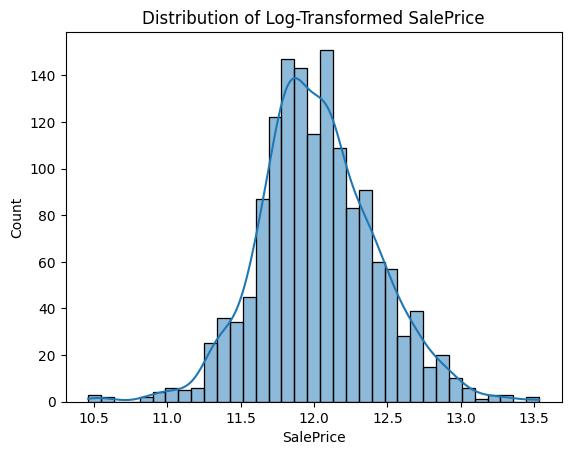

Skewness after log-transform: 0.12


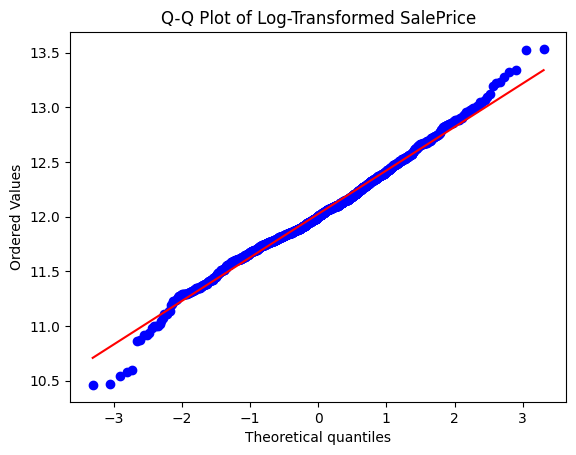

In [3]:
# Log-transform target due to skewness
train['SalePrice'] = np.log1p(train['SalePrice'])
sns.histplot(train['SalePrice'], kde=True)
plt.title('Distribution of Log-Transformed SalePrice')
plt.show()
print(f"Skewness after log-transform: {train['SalePrice'].skew():.2f}")
# Q-Q plot
plt.figure()
probplot(train['SalePrice'], plot=plt)
plt.title('Q-Q Plot of Log-Transformed SalePrice')
plt.show()


In [4]:
# Save target and combine
y_train = train['SalePrice'].copy()
all_data = pd.concat([train.drop('SalePrice', axis=1), test], axis=0).reset_index(drop=True)
print(f"Combined data shape: {all_data.shape}")


Combined data shape: (2919, 79)


In [5]:
# Missing values
missing = all_data.isnull().sum().sort_values(ascending=False)
percent_missing = (missing / all_data.shape[0]) * 100
missing_df = pd.concat([missing, percent_missing], axis=1, keys=['TotalMissing', 'PercentMissing'])
display(missing_df[missing_df['TotalMissing'] > 0].head(20))


,TotalMissing,PercentMissing
PoolQC,2909,99.657417
MiscFeature,2814,96.402878
Alley,2721,93.216855
Fence,2348,80.438506
MasVnrType,1766,60.500171
FireplaceQu,1420,48.646797
LotFrontage,486,16.649538
GarageYrBlt,159,5.447071
GarageFinish,159,5.447071
GarageQual,159,5.447071


## Explicit Ordinal Mappings
We define explicit mappings for ordinal features to ensure correct order rather than relying on LabelEncoder's alphabetical order.


In [6]:
# Define ordinal mappings
ordinal_mappings = {
    'ExterQual': {'Ex':5, 'Gd':4, 'TA':3, 'Fa':2, 'Po':1},
    'ExterCond': {'Ex':5, 'Gd':4, 'TA':3, 'Fa':2, 'Po':1},
    'BsmtQual': {'Ex':5, 'Gd':4, 'TA':3, 'Fa':2, 'Po':1, np.nan:0},
    'BsmtCond': {'Ex':5, 'Gd':4, 'TA':3, 'Fa':2, 'Po':1, np.nan:0},
    'HeatingQC': {'Ex':5, 'Gd':4, 'TA':3, 'Fa':2, 'Po':1},
    'KitchenQual': {'Ex':5, 'Gd':4, 'TA':3, 'Fa':2, 'Po':1},
    'FireplaceQu': {'Ex':5, 'Gd':4, 'TA':3, 'Fa':2, 'Po':1, np.nan:0},
    'GarageQual': {'Ex':5, 'Gd':4, 'TA':3, 'Fa':2, 'Po':1, np.nan:0},
    'GarageCond': {'Ex':5, 'Gd':4, 'TA':3, 'Fa':2, 'Po':1, np.nan:0},
    'PoolQC': {'Ex':4, 'Gd':3, 'TA':2, 'Fa':1, np.nan:0},
    'BsmtExposure': {'Gd':4, 'Av':3, 'Mn':2, 'No':1, np.nan:0},
    'BsmtFinType1': {'GLQ':6, 'ALQ':5, 'BLQ':4, 'Rec':3, 'LwQ':2, 'Unf':1, np.nan:0},
    'BsmtFinType2': {'GLQ':6, 'ALQ':5, 'BLQ':4, 'Rec':3, 'LwQ':2, 'Unf':1, np.nan:0},
    'Functional': {'Typ':8, 'Min1':7, 'Min2':6, 'Mod':5, 'Maj1':4, 'Maj2':3, 'Sev':2, 'Sal':1, np.nan:0},
    'Fence': {'GdPrv':4, 'MnPrv':3, 'GdWo':2, 'MnWo':1, np.nan:0},
    'LotShape': {'Reg':4, 'IR1':3, 'IR2':2, 'IR3':1},
    'Utilities': {'AllPub':3, 'NoSewr':2, 'NoSeWa':1, np.nan:0},
    'LandSlope': {'Gtl':3, 'Mod':2, 'Sev':1},
    'PavedDrive': {'Y':2, 'P':1, 'N':0},
    'Street': {'Pave':1, 'Grvl':0},
    'CentralAir': {'Y':1, 'N':0},
    # Add any others as needed
}
# Apply mappings where present
for col, mapping in ordinal_mappings.items():
    if col in all_data.columns:
        all_data[col] = all_data[col].map(mapping).fillna(0).astype(int)


## Missing Value Imputation
We impute missing values based on domain knowledge: NA meaning absence (e.g., no pool), numeric zeros, or group medians.


In [7]:
# Example: Impute features where NA means 'None'
na_none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu', 'GarageType',
                'GarageFinish', 'GarageQual', 'GarageCond', 'BsmtQual', 'BsmtCond',
                'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType', 'Electrical']
for col in na_none_cols:
    if col in all_data.columns:
        # For numeric columns previously mapped to ordinal, missing mapped to 0 above; for strings, fill 'None'
        if all_data[col].dtype == object:
            all_data[col] = all_data[col].fillna('None')
        else:
            all_data[col] = all_data[col].fillna(0)

# Numeric features where NA means 0
na_zero_cols = ['GarageYrBlt', 'GarageArea', 'GarageCars', 'BsmtFinSF1', 'BsmtFinSF2',
                'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']
for col in na_zero_cols:
    if col in all_data.columns:
        all_data[col] = all_data[col].fillna(0)

# Fill LotFrontage by neighborhood median
if 'LotFrontage' in all_data.columns:
    all_data['LotFrontage'] = all_data.groupby('Neighborhood')['LotFrontage']                                    .transform(lambda x: x.fillna(x.median()))

# Any remaining numeric missing: fill with median
numeric_cols = all_data.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    if all_data[col].isnull().sum() > 0:
        all_data[col] = all_data[col].fillna(all_data[col].median())

# Any remaining categorical missing: fill with mode
categorical_cols = all_data.select_dtypes(include=['object']).columns
for col in categorical_cols:
    if all_data[col].isnull().sum() > 0:
        all_data[col] = all_data[col].fillna(all_data[col].mode()[0])

# Verify no missing
print("Total missing after imputation:", all_data.isnull().sum().sum())


Total missing after imputation: 0


## Feature Engineering
Create combined features and temporal features.


In [8]:
# Total square footage
if all(col in all_data.columns for col in ['TotalBsmtSF', '1stFlrSF', '2ndFlrSF']):
    all_data['TotalSF'] = all_data['TotalBsmtSF'] + all_data['1stFlrSF'] + all_data['2ndFlrSF']

# Total bathrooms
if all(col in all_data.columns for col in ['FullBath', 'HalfBath', 'BsmtFullBath', 'BsmtHalfBath']):
    all_data['TotalBath'] = (all_data['FullBath'] + 0.5 * all_data['HalfBath'] +
                             all_data['BsmtFullBath'] + 0.5 * all_data['BsmtHalfBath'])

# Binary features for presence
if 'PoolArea' in all_data.columns:
    all_data['HasPool'] = (all_data['PoolArea'] > 0).astype(int)
if 'GarageArea' in all_data.columns:
    all_data['HasGarage'] = (all_data['GarageArea'] > 0).astype(int)
if 'TotalBsmtSF' in all_data.columns:
    all_data['HasBsmt'] = (all_data['TotalBsmtSF'] > 0).astype(int)
if 'Fireplaces' in all_data.columns:
    all_data['HasFireplace'] = (all_data['Fireplaces'] > 0).astype(int)

# Temporal features: Age and Remodel Age
if 'YrSold' in all_data.columns and 'YearBuilt' in all_data.columns:
    all_data['YrSold'] = all_data['YrSold'].astype(int)  # keep numeric for age diff
    all_data['Age'] = all_data['YrSold'] - all_data['YearBuilt']

if 'YrSold' in all_data.columns and 'YearRemodAdd' in all_data.columns:
    all_data['AgeRemod'] = all_data['YrSold'] - all_data['YearRemodAdd']


## Convert Numeric IDs to Categorical
Some numeric codes represent categories rather than continuous values.


In [9]:
for col in ['MSSubClass', 'MoSold']:
    if col in all_data.columns:
        all_data[col] = all_data[col].astype(str)
# YrSold used for Age above; we keep Year sold numeric for modeling temporal if desired


## Handle Skewness
Apply Box-Cox transformation to numeric features with high skew.


In [10]:
# Identify numeric features excluding target
numeric_feats = all_data.select_dtypes(include=[np.number]).columns

# Compute skewness
skewness = all_data[numeric_feats].apply(lambda x: skew(x.dropna()))
skewed_feats = skewness[abs(skewness) > 0.75].index
print("Skewed features:", list(skewed_feats))

# Apply Box-Cox (using lambda=0.15) to skewed features; ensure non-negative
for feat in skewed_feats:
    # Add 1 to ensure positive if zero values exist
    all_data[feat] = boxcox1p(all_data[feat], 0.15)


Skewed features: ['LotFrontage', 'LotArea', 'Street', 'LotShape', 'Utilities', 'LandSlope', 'MasVnrArea', 'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'CentralAir', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtHalfBath', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Functional', 'GarageYrBlt', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'PoolQC', 'Fence', 'MiscVal', 'TotalSF', 'HasPool', 'HasGarage', 'HasBsmt']


## One-Hot Encoding
Convert categorical variables into dummy/indicator variables.


In [11]:
# Identify categorical features
categorical_feats = all_data.select_dtypes(include=['object']).columns
print("Categorical features for encoding:", list(categorical_feats))

# One-hot encode
all_data = pd.get_dummies(all_data, columns=categorical_feats, drop_first=True)
print("Shape after one-hot encoding:", all_data.shape)


Categorical features for encoding: ['MSSubClass', 'MSZoning', 'Alley', 'LandContour', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'Electrical', 'GarageType', 'GarageFinish', 'MiscFeature', 'MoSold', 'SaleType', 'SaleCondition']
Shape after one-hot encoding: (2919, 237)


In [12]:
# Split combined data
X_train = all_data[:len(train)].copy()
X_test = all_data[len(train):].copy()
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


X_train shape: (1460, 237)
X_test shape: (1459, 237)


## Feature Scaling
Scale numeric features using StandardScaler (helpful for linear models).


In [13]:
# Scale numeric columns for linear models
scaler = StandardScaler()
# Fit scaler on training numeric features and transform both train and test
numeric_feats = X_train.select_dtypes(include=[np.number]).columns
X_train[numeric_feats] = scaler.fit_transform(X_train[numeric_feats])
X_test[numeric_feats] = scaler.transform(X_test[numeric_feats])


In [14]:
# Define RMSE CV function
def rmsle_cv(model, X, y):
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    rmse = np.sqrt(-cross_val_score(model, X, y, scoring="neg_mean_squared_error", cv=kf))
    return rmse


## Modeling
Train baseline models and compare via cross-validation.


In [15]:
# Lasso Regression
lasso = Lasso(alpha=0.0005, random_state=1)
score = rmsle_cv(lasso, X_train, y_train)
print(f"Lasso CV RMSE: {score.mean():.4f} ± {score.std():.4f}")

# Ridge Regression
ridge = Ridge(alpha=1.0)
score = rmsle_cv(ridge, X_train, y_train)
print(f"Ridge CV RMSE: {score.mean():.4f} ± {score.std():.4f}")

# Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
score = rmsle_cv(rf, X_train, y_train)
print(f"Random Forest CV RMSE: {score.mean():.4f} ± {score.std():.4f}")

# Gradient Boosting Regressor
gbr = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
score = rmsle_cv(gbr, X_train, y_train)
print(f"Gradient Boosting CV RMSE: {score.mean():.4f} ± {score.std():.4f}")


Lasso CV RMSE: 0.1312 ± 0.0222
Ridge CV RMSE: 0.1321 ± 0.0212
Random Forest CV RMSE: 0.1431 ± 0.0183
Gradient Boosting CV RMSE: 0.1317 ± 0.0167


### Hyperparameter Tuning for Random Forest (Example)
Using RandomizedSearchCV to find better hyperparameters.


In [16]:
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
rf_model = RandomForestRegressor(random_state=42)
rs = RandomizedSearchCV(rf_model, param_distributions=param_dist, n_iter=10, cv=3,
                        scoring='neg_mean_squared_error', random_state=42, n_jobs=-1)
rs.fit(X_train, y_train)
print("Best RF params:", rs.best_params_)
best_rf = rs.best_estimator_
score = rmsle_cv(best_rf, X_train, y_train)
print(f"Tuned RF CV RMSE: {score.mean():.4f} ± {score.std():.4f}")


KeyboardInterrupt: 

## Feature Importance
Visualize top features from the tuned Random Forest.


In [ ]:
# Fit on full training data
best_rf.fit(X_train, y_train)
# Get importances
importances = pd.Series(best_rf.feature_importances_, index=X_train.columns)
top_feats = importances.sort_values(ascending=False).head(20)
plt.figure(figsize=(10,6))
sns.barplot(x=top_feats.values, y=top_feats.index)
plt.title('Top 20 Feature Importances')
plt.tight_layout()
plt.show()


## Residual Analysis
Check residuals of the tuned model.


In [ ]:
# Predict on training set
preds_train = best_rf.predict(X_train)
residuals = y_train - preds_train
# Residual histogram
plt.figure()
sns.histplot(residuals, kde=True)
plt.title('Residuals Distribution')
plt.show()
# Predicted vs Actual
plt.figure(figsize=(6,6))
plt.scatter(preds_train, y_train, alpha=0.3)
plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'r--')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Predicted vs Actual (log scale)')
plt.show()


## Final Model and Submission
Train final model on full training data and generate predictions for test set. Reverse log-transform via expm1.


In [ ]:
# Train final model on all train data
final_model = best_rf  # or choose preferred model
final_model.fit(X_train, y_train)
# Predict on test
preds_test = final_model.predict(X_test)
# Reverse log transform
final_preds = np.expm1(preds_test)
# Prepare submission DataFrame if test_ID is available
if test_ID is not None:
    submission = pd.DataFrame({'Id': test_ID, 'SalePrice': final_preds})
    submission.to_csv('submission.csv', index=False)
    print('Submission file saved as submission.csv')
else:
    print('test_ID not found; cannot save submission with Id.')
